In [ ]:
import yfinance as yf
import datetime as dt
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import numpy as np


In [ ]:
# assets = ['BTC-USD', 'GC=F', 'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'PNC', 'USB','AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'TSLA', 'INTC', 'CSCO','JNJ', 'PFE', 'UNH', 'MRK', 'LLY', 'ABBV', 'GILD', 'TMO', 'MRNA','AMT', 'PLD', 'CCI', 'SPG', 'PSA', 'EQIX', 'O', 'VNO', 'AVB','SCHW', 'BLK', 'GS', 'MS', 'RJF', 'TROW', 'AMP', 'IBKR']
# assets = ['GILD','MRK']
assets = ['UUP','GC=F','KC=F','ZW=F','ZS=F','SB=F','HG=F','JPM', 'BAC','TSLA','AAPL','KO','BTC-USD','USDJPY=X','GBPUSD=X','VNQ','IEF']

data1 = yf.download(assets, period = 'max')['Close'].ffill().dropna()
print(data1.index[0])
df = data1.reset_index()
df.drop(columns=['Date'], inplace=True)
data = df.pct_change()
# data






[*********************100%***********************]  17 of 17 completed


2014-09-17 00:00:00


In [ ]:
num_assets  = 5
threshold = 0.8
balance_time = 120

In [ ]:
def port(start):

  # checked_data = data[start - 252:start]
  # returns = checked_data.dropna()
  df_check = df[start-252:start]
  long_period = 20
  ret_check= pd.DataFrame()
  for column in df_check:
    symbol = pd.DataFrame()
    symbol['price'] = df_check[column]
    symbol['MA_long'] = symbol['price'].rolling(window=long_period).mean()
    symbol['MA_short'] = symbol['price'].rolling(window=5).mean()
    symbol['signal'] = np.where(symbol['MA_short'] > symbol['MA_long'], 1, -1)
    symbol['ret'] = symbol['price'].pct_change()
    symbol['strategy'] = symbol['signal'].shift(1) * symbol['ret']
    ret_check = pd.concat([ret_check, symbol['strategy'].rename(column)], axis=1)
  corr_matrix = ret_check.corr()
  mean_correlation = corr_matrix.mean()

  # Filter assets with mean correlation below the threshold
  eligible_assets = mean_correlation[mean_correlation < threshold]

  # Select up to `num_assets` assets with the lowest mean correlations
  selected_assets_raw = eligible_assets.nsmallest(num_assets).index
  port = [item.replace('returns', '').strip() for item in selected_assets_raw]
  end = start + balance_time

  df_port = df[port][start-long_period:end]
  ret_combined= pd.DataFrame()
  for column in df_port:
    symbol = pd.DataFrame()
    symbol['price'] = df_port[column]
    symbol['MA_long'] = symbol['price'].rolling(window=long_period).mean()
    symbol['MA_short'] = symbol['price'].rolling(window=5).mean()
    symbol['signal'] = np.where(symbol['MA_short'] > symbol['MA_long'], 1, -1)
    symbol['ret'] = symbol['price'].pct_change()
    symbol['strategy'] = symbol['signal'].shift(1) * symbol['ret']
    ret_combined = pd.concat([ret_combined, symbol['strategy']], axis=1) # Using ret_comnbined


  weight = 1/len(port)
  port_return = ((ret_combined*weight).sum(axis=1)+1).cumprod()[end-1] - 1

  return port,port_return

#weight by MA return
def port(start):

  # checked_data = data[start - 252:start]
  # returns = checked_data.dropna()
  df_check = df[start-252:start]
  long_period = 20
  ret_check= pd.DataFrame()
  for column in df_check:
    symbol = pd.DataFrame()
    symbol['price'] = df_check[column]
    symbol['MA_long'] = symbol['price'].rolling(window=long_period).mean()
    symbol['MA_short'] = symbol['price'].rolling(window=5).mean()
    symbol['signal'] = np.where(symbol['MA_short'] > symbol['MA_long'], 1, -1)
    symbol['ret'] = symbol['price'].pct_change()
    symbol['strategy'] = symbol['signal'].shift(1) * symbol['ret']
    ret_check = pd.concat([ret_check, symbol['strategy'].rename(column)], axis=1)
  corr_matrix = ret_check.corr()
  mean_correlation = corr_matrix.mean()

  # Filter assets with mean correlation below the threshold
  eligible_assets = mean_correlation[mean_correlation < threshold]

  # Select up to `num_assets` assets with the lowest mean correlations
  selected_assets_raw = eligible_assets.nsmallest(num_assets).index
  port = [item.replace('returns', '').strip() for item in selected_assets_raw]
  end = start + balance_time

  df_port = df[port][start-long_period:end]
  ret_combined= pd.DataFrame()
  for column in df_port:
    symbol = pd.DataFrame()
    symbol['price'] = df_port[column]
    symbol['MA_long'] = symbol['price'].rolling(window=long_period).mean()
    symbol['MA_short'] = symbol['price'].rolling(window=5).mean()
    symbol['signal'] = np.where(symbol['MA_short'] > symbol['MA_long'], 1, -1)
    symbol['ret'] = symbol['price'].pct_change()
    symbol['strategy'] = symbol['signal'].shift(1) * symbol['ret']
    ret_combined = pd.concat([ret_combined, symbol['strategy']], axis=1) # Using ret_comnbined


  weight = 1/len(port)
  port_return = ((ret_combined*weight).sum(axis=1)+1).cumprod()[end-1] - 1

  return port,port_return

In [ ]:
port(1000)

(['GBPUSD=X', 'BTC-USD', 'KC=F', 'VNQ', 'ZW=F'], 0.2073257548913623)

In [ ]:
portfolio_returns = []

i = 252
while i < data.index[-1]:
  portfolio, portfolio_return = port( i)
  portfolio_returns.append(portfolio_return)
  print (f'At {i} port is {portfolio} \n portfolio_return is {portfolio_return}')
  if i + 2*balance_time <= data.index[-1]:
    i += balance_time
  else:
    break


At 252 port is ['GBPUSD=X', 'GC=F', 'BTC-USD', 'KO', 'ZW=F'] 
 portfolio_return is 0.023722391899333006
At 372 port is ['GBPUSD=X', 'GC=F', 'IEF', 'HG=F', 'ZW=F'] 
 portfolio_return is -0.0076162969362287836
At 492 port is ['BTC-USD', 'ZW=F', 'KC=F', 'ZS=F', 'HG=F'] 
 portfolio_return is 0.037586457992978106
At 612 port is ['BTC-USD', 'ZS=F', 'GBPUSD=X', 'USDJPY=X', 'KC=F'] 
 portfolio_return is -0.03897362716625308
At 732 port is ['GBPUSD=X', 'BTC-USD', 'TSLA', 'USDJPY=X', 'HG=F'] 
 portfolio_return is 0.12465423395005404
At 852 port is ['GBPUSD=X', 'VNQ', 'HG=F', 'BTC-USD', 'ZW=F'] 
 portfolio_return is -0.02420488783866781
At 972 port is ['BTC-USD', 'GBPUSD=X', 'KC=F', 'SB=F', 'ZW=F'] 
 portfolio_return is 0.16273483601450178
At 1092 port is ['ZW=F', 'GBPUSD=X', 'UUP', 'AAPL', 'USDJPY=X'] 
 portfolio_return is 0.011774495421540632
At 1212 port is ['GBPUSD=X', 'AAPL', 'ZW=F', 'USDJPY=X', 'BTC-USD'] 
 portfolio_return is 0.012944416213085175
At 1332 port is ['USDJPY=X', 'ZW=F', 'IEF',

0.500946752295788


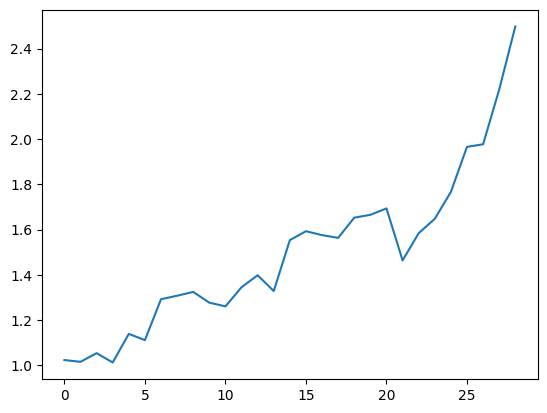

In [ ]:
portfolio_returns = pd.Series(portfolio_returns)
port_cum = (1+portfolio_returns).cumprod()
port_sharpe = portfolio_returns.mean()/portfolio_returns.std()
print(port_sharpe)
plt.plot(port_cum)